# F3 (Pro版)：多 FMU 协同仿真 —— 车辆动力学 × 动力电池双从站与主算法通信步长效应

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链4：跨工具链协同仿真与软件工程** 的终极大课。
> 在现代汽车研发体系中，任何一款整车仿真都不可能由单一团队或单一软件独占完成：底盘动力学组在 VI-CarRealTime 或 Dymola 中搭建车身六自由度模型，动力电池电芯组在 MATLAB/Simulink 中搭建等效电路模型，电驱电机组在 JMAG 中导出电磁热耦合模型。将这些异构模型高效、稳定地链接在一起的核心范式就是 **多 FMU 协同仿真 (Multi-FMU Co-Simulation)**。
> 协同仿真的核心挑战在于**主算法（Master Algorithm）设计**与**通信步长 $H$ 的权衡**：
> 1. **主算法解耦机制**：**Jacobi 算法（并行通信）** 允许各从站并发推进，但强行引入了一整步的耦合信号延迟（$O(H)$ 截断时滞）；而 **Gauss-Seidel 算法（串行流水线）** 优先推进上游车辆模型并将新鲜车速注入下游电池模型，牺牲了并行性但大幅压制了数值漂移。
> 2. **通信步长 $H$ 效应**：$H$ 过小会导致进程间上下文切换与 IPC 接口开销激增；$H$ 过大则可能破坏多领域数值稳定性甚至引发发散。
> 
> 本实验加载真实的两个 FMI 2.0 CS 规范黑盒（`VehicleLongitudinal.fmu` 与 `BatterySimple.fmu`），以 $H = 0.001\,\text{s}$ 作为准单体参考解（Quasi-Monolithic Reference），深入测试 Jacobi 与 Gauss-Seidel 主算法在不同通信步长下的收敛阶次，实测速度误差仅 **0.02%**（判据 $< 1.0\%$）、位移误差 **1.00%**（判据 $< 2.0\%$），彻底掌握多工具链系统集成的底层精髓。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & 双 FMU 资源定位)**：执行阶段一，确认 `fmpy` 运行就绪，定位整车与电池两个 FMI 2.0 CS 二进制黑盒；
* **第二步 (双从站接口契约与耦合拓扑分析)**：阶段二解析 `VehicleLongitudinal.fmu` 与 `BatterySimple.fmu` 暴露的输入输出变量引用（ValueReference）；
* **第三步 (高可靠主算法引擎构建)**：阶段三构建支持 **Jacobi 并行** 与 **Gauss-Seidel 串行流水线** 的 FMPy 双从站主推进循环；
* **第四步 (准单体超细参考真值生成)**：阶段四执行 $H = 0.001\,\text{s}$（10,000 步）的高精度参考仿真，确立数学基准真值；
* **第五步 (多通信步长全景参数扫描)**：阶段五对 $H \in [0.01, 0.1, 0.5]\,\text{s}$ 进行网格化扫参，量化时滞相位差与能量累积漂移；
* **第六步 (工程级精度断言与误差分析)**：阶段六严格验证速度误差（实测 **0.02%** $< 1.0\%$）与位置误差（实测 **1.00%** $< 2.0\%$）；
* **第七步 (多维感知与 4合1 协仿真仪表盘)**：阶段七生成车速、位移、电池 SOC/端电压及步长误差衰减 4合1 工程仪表盘；
* **第八步 (原生 HTML5/Canvas 双从站总线动态交互台)**：阶段八运行**交互式 Canvas 协仿真数据总线透视仪**，动画演示主控时钟、数据包交互时序与能量流；
* **第九步 (官方自动评分与数据链归档)**：阶段九对接平台官方评测器，验证多 FMU 协仿真指标（判据：`v_err_pct < 1.0%`、`x_err_pct < 2.0%`），获取官方 100/100 成绩单。

---

### 📚 核心理论与物理机理：多领域协同仿真与主算法时序

1. **双 FMU 耦合物理机理**：
   - **车辆纵向动力学 FMU (`VehicleLongitudinal`)**：
     $$m \frac{dv}{dt} = F_{\text{motor}} - \frac{1}{2} \rho C_d A v^2 - m g f_{\text{roll}}, \quad \frac{dx}{dt} = v$$
     输入：电机驱动力 $F_{\text{motor}}$ (N)；输出：车速 $v$ (m/s)、累计位移 $x$ (m)。
   - **动力电池等效电路 FMU (`BatterySimple`)**：
     $$P_{\text{elec}} = \frac{F_{\text{motor}} \cdot \max(v, 0.1)}{\eta_{\text{driveline}}}$$
     $$\frac{d\text{SOC}}{dt} = -\frac{I_{\text{bat}}}{Q_{\text{nom}} \times 3600}, \quad V_{\text{term}} = V_{\text{ocv}}(\text{SOC}) - I_{\text{bat}} R_0$$
     输入：电功率需求 $P_{\text{elec}}$ (W)；输出：荷电状态 $\text{SOC}$、端电压 $V_{\text{term}}$ (V)。

2. **Jacobi vs Gauss-Seidel 主算法时钟对齐**：
   - **Jacobi 主算法（显式单步时滞）**：
     在区间 $[t_k, t_k + H]$ 内，两从站均采用时刻 $t_k$ 的旧耦合值：
     $$P_{\text{elec}}^{(k)} = \frac{F^{(k)} v(t_k)}{\eta}$$
     $$\text{veh.doStep}(t_k, H), \quad \text{bat.doStep}(t_k, H)$$
     两子系统可在多核 CPU 上完全并发运行，但引入 $O(H)$ 的能量滞后误差。
   - **Gauss-Seidel 主算法（流水线刷新）**：
     车辆动力学优先推进：$\text{veh.doStep}(t_k, H) \implies v(t_{k+1})$。
     立即用最新速度计算电功率：$P_{\text{elec}}^{(k+1)} = \frac{F^{(k)} v(t_{k+1})}{\eta}$。
     再驱动电池从站：$\text{bat.doStep}(t_k, H) \implies \text{SOC}(t_{k+1})$。
     消除单向耦合延迟，在相同步长下通常具备更高的数值保真度。


In [1]:
# 阶段一：环境自检与双 FMU 资源路径发现
import os, sys, shutil, time, json
import numpy as np
import matplotlib.pyplot as plt

# 鲁棒搜索平台共享目录 labs
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break
if LABS_ROOT is None:
    raise FileNotFoundError("未定位到 labs 根目录，请确认实验环境部署。")
if LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

import fmpy
from fmpy import read_model_description, extract
from fmpy.fmi2 import FMU2Slave

# 定位平台预置的两个真实 FMI 2.0 CS FMU 文件
CANDIDATE_FMU_DIRS = [
    os.path.join(LABS_ROOT, "scenarios/F_fmu/F3_multifmu/fmu"),
    "/opt/ievlab/scenarios/labs/scenarios/F_fmu/F3_multifmu/fmu",
    "labs/scenarios/F_fmu/F3_multifmu/fmu"
]
FMU_DIR = next((d for d in CANDIDATE_FMU_DIRS if os.path.isdir(d)), None)
assert FMU_DIR is not None, "未找到 FMU 目录，请检查 labs/scenarios/F_fmu/F3_multifmu/fmu/"

VEH_FMU = os.path.join(FMU_DIR, "VehicleLongitudinal.fmu")
BAT_FMU = os.path.join(FMU_DIR, "BatterySimple.fmu")

assert os.path.exists(VEH_FMU), f"缺失车辆动力学 FMU: {VEH_FMU}"
assert os.path.exists(BAT_FMU), f"缺失动力电池 FMU: {BAT_FMU}"

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")
print(f"✓ FMPy 动力学库版本: {fmpy.__version__}")
print(f"✓ 车辆动力学 FMU: {VEH_FMU} ({os.path.getsize(VEH_FMU):,} 字节)")
print(f"✓ 动力电池 FMU  : {BAT_FMU} ({os.path.getsize(BAT_FMU):,} 字节)")


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs
✓ FMPy 动力学库版本: 0.3.22
✓ 车辆动力学 FMU: /home/jovyan/labs/scenarios/F_fmu/F3_multifmu/fmu/VehicleLongitudinal.fmu (4,728 字节)
✓ 动力电池 FMU  : /home/jovyan/labs/scenarios/F_fmu/F3_multifmu/fmu/BatterySimple.fmu (4,707 字节)


---
## 阶段二：双从站接口契约与变量引用审计

在构建多模型耦合总线前，必须首先审计两模型的输入输出因果关系与值引用（ValueReference）：
- `VehicleLongitudinal`：$F_{\text{motor}}$ (VR 0, input), $v$ (VR 1, output), $x$ (VR 2, output)；
- `BatterySimple`：$P_{\text{elec}}$ (VR 0, input), $\text{SOC}$ (VR 1, output), $V_{\text{term}}$ (VR 2, output)。


In [2]:
# 阶段二：解析两模型的 modelDescription.xml
VR_F, VR_V, VR_X = 0, 1, 2       # 车辆从站 VR
VR_P, VR_SOC, VR_VT = 0, 1, 2   # 电池从站 VR

md_veh = read_model_description(VEH_FMU)
md_bat = read_model_description(BAT_FMU)

print("=" * 68)
print("             IEV CloudLab F3 双 FMU 接口变量因果契约             ")
print("=" * 68)
print(f"【车辆从站】: {md_veh.modelName} (FMI {md_veh.fmiVersion} CS)")
for v in md_veh.modelVariables:
    print(f"  • {v.name:<10} | VR={v.valueReference} | {v.causality:<8} | {v.variability:<10} | {v.description}")

print(f"\n【电池从站】: {md_bat.modelName} (FMI {md_bat.fmiVersion} CS)")
for v in md_bat.modelVariables:
    print(f"  • {v.name:<10} | VR={v.valueReference} | {v.causality:<8} | {v.variability:<10} | {v.description}")
print("=" * 68)
print("✅ 双 FMU 接口契约审计完成，单向松耦合拓扑成立！")


             IEV CloudLab F3 双 FMU 接口变量因果契约             
【车辆从站】: VehicleLongitudinal (FMI 2.0 CS)
  • F_motor    | VR=0 | input    | continuous | None
  • v          | VR=1 | output   | continuous | None
  • x          | VR=2 | output   | continuous | None
  • mass       | VR=3 | parameter | fixed      | None

【电池从站】: BatterySimple (FMI 2.0 CS)
  • P_elec     | VR=0 | input    | continuous | None
  • SOC        | VR=1 | output   | continuous | None
  • V_term     | VR=2 | output   | continuous | None
  • Q_Ah       | VR=3 | parameter | fixed      | None
✅ 双 FMU 接口契约审计完成，单向松耦合拓扑成立！


---
## 阶段三：构建支持 Jacobi 与 Gauss-Seidel 的协同仿真主算法引擎

封装高可靠的实例化、初始化与推进循环：
- 严格遵循 FMI 2.0 状态机生命周期；
- `run_cosim(H, method)` 支持用户配置通信步长 $H$ 与主算法模式（`"jacobi"` vs `"gauss-seidel"`）；
- 在推进循环结束时自动执行 `terminate()` 与 `freeInstance()`，并安全清理解包临时缓存。


In [3]:
# 阶段三：主算法通用协仿真引擎
def make_slave(fmu_path, instance_name):
    """通过 FMPy 真实实例化 FMI 2.0 CS 从站"""
    md = read_model_description(fmu_path)
    unzipdir = extract(fmu_path)
    slave = FMU2Slave(
        guid=md.guid,
        unzipDirectory=unzipdir,
        modelIdentifier=md.coSimulation.modelIdentifier,
        instanceName=instance_name
    )
    slave.instantiate()
    return slave, unzipdir

def init_slave(slave):
    slave.setupExperiment(startTime=0.0)
    slave.enterInitializationMode()
    slave.exitInitializationMode()

def run_cosim(H, method="gauss-seidel", t_end=10.0, F_cmd=3000.0, eta=0.9):
    """
    执行双 FMU 闭环协同仿真
    :param H: 通信步长 (s)
    :param method: 主算法模式 ('jacobi' 或 'gauss-seidel')
    :param t_end: 仿真终止时间 (s)
    :param F_cmd: 电机恒定驱动力 (N)
    :param eta: 传动系统机械-电转换综合效率
    """
    veh, veh_tmp = make_slave(VEH_FMU, "veh_slave")
    bat, bat_tmp = make_slave(BAT_FMU, "bat_slave")
    try:
        init_slave(veh)
        init_slave(bat)
        
        t = 0.0
        v = veh.getReal([VR_V])[0]
        hist = []
        
        while t < t_end - 1e-12:
            if method == "jacobi":
                # Jacobi (并行): 两个从站均基于上一步历史车速推进
                P_elec = F_cmd * max(v, 0.1) / eta
                veh.setReal([VR_F], [F_cmd])
                bat.setReal([VR_P], [P_elec])
                veh.doStep(t, H, True)
                bat.doStep(t, H, True)
            elif method == "gauss-seidel":
                # Gauss-Seidel (串行流水线): 车辆优先推进，电池使用瞬时新鲜车速
                veh.setReal([VR_F], [F_cmd])
                veh.doStep(t, H, True)
                v_new = veh.getReal([VR_V])[0]
                P_elec = F_cmd * max(v_new, 0.1) / eta
                bat.setReal([VR_P], [P_elec])
                bat.doStep(t, H, True)
            else:
                raise ValueError("method 必须为 'jacobi' 或 'gauss-seidel'")
                
            v = veh.getReal([VR_V])[0]
            x = veh.getReal([VR_X])[0]
            soc = bat.getReal([VR_SOC])[0]
            vt = bat.getReal([VR_VT])[0]
            t += H
            hist.append((t, v, x, soc, vt, P_elec))
            
        return np.array(hist)
    finally:
        for s in (veh, bat):
            s.terminate()
            s.freeInstance()
        shutil.rmtree(veh_tmp, ignore_errors=True)
        shutil.rmtree(bat_tmp, ignore_errors=True)

print("✓ 协同仿真主算法引擎构建就绪: run_cosim(H, method)")


✓ 协同仿真主算法引擎构建就绪: run_cosim(H, method)


---
## 阶段四：准单体参考解与通信步长全景扫描

在多模型协同仿真评估中，由于缺乏解析闭式解，工程标准方法是采用**极小步长（$H = 0.001\,\text{s}$，1 kHz）**的 Gauss-Seidel 解作为准单体（Quasi-Monolithic）参考基准。
随后，分别对 **Jacobi** 与 **Gauss-Seidel** 在通信步长 $H \in [0.01, 0.1, 0.5]\,\text{s}$ 下进行全景扫描，观察数值发散与时滞偏离。


In [4]:
# 阶段四：生成准单体参考真值与多步长对比
print("🚀 正在计算准单体超细参考真值 (H = 0.001s, 10,000 步)...")
t0 = time.time()
ref = run_cosim(H=0.001, method="gauss-seidel", t_end=10.0)
print(f"✓ 参考真值计算完成！耗时: {time.time()-t0:.2f} s")
print(f"• 终点时刻参考真值: 车速 v = {ref[-1, 1]:.2f} m/s | 位移 x = {ref[-1, 2]:.1f} m | SOC = {ref[-1, 3]:.4f}")

# 扫描不同通信步长
results = {}
for method in ["gauss-seidel", "jacobi"]:
    for H in [0.01, 0.1, 0.5]:
        h = run_cosim(H, method, t_end=10.0)
        results[(method, H)] = h
        print(f"  [{method.upper():<12}] H={H:.2f}s: 终点 v={h[-1, 1]:.2f} m/s, 位移={h[-1, 2]:.1f} m, SOC={h[-1, 3]:.4f} (步数: {len(h)})")

print("✅ 全景参数仿真计算全部顺利收敛！")


🚀 正在计算准单体超细参考真值 (H = 0.001s, 10,000 步)...


✓ 参考真值计算完成！耗时: 0.24 s
• 终点时刻参考真值: 车速 v = 18.72 m/s | 位移 x = 94.4 m | SOC = 0.5715
  [GAUSS-SEIDEL] H=0.01s: 终点 v=18.72 m/s, 位移=94.4 m, SOC=0.5715 (步数: 1000)
  [GAUSS-SEIDEL] H=0.10s: 终点 v=18.73 m/s, 位移=95.3 m, SOC=0.5717 (步数: 100)
  [GAUSS-SEIDEL] H=0.50s: 终点 v=18.74 m/s, 位移=99.1 m, SOC=0.5724 (步数: 20)
  [JACOBI      ] H=0.01s: 终点 v=18.72 m/s, 位移=94.4 m, SOC=0.5720 (步数: 1000)
  [JACOBI      ] H=0.10s: 终点 v=18.73 m/s, 位移=95.3 m, SOC=0.5763 (步数: 100)
  [JACOBI      ] H=0.50s: 终点 v=18.74 m/s, 位移=99.1 m, SOC=0.5955 (步数: 20)
✅ 全景参数仿真计算全部顺利收敛！


---
## 阶段五：工程级指标定量分析与断言验证

对比 $H = 0.1\,\text{s}$（经典车辆网联通信周期 100ms）下 Jacobi 与 Gauss-Seidel 的末端相对误差：
$$\text{v\_err\_pct} = \frac{|v_{\text{end}}(H) - v_{\text{ref}}|}{v_{\text{ref}}} \times 100\%$$
$$\text{x\_err\_pct} = \frac{|x_{\text{end}}(H) - x_{\text{ref}}|}{x_{\text{ref}}} \times 100\%$$
要求：
1. 速度相对误差 $\text{v\_err\_pct} < 1.0\%$（实测仅 $0.02\%$）；
2. 位置相对误差 $\text{x\_err\_pct} < 2.0\%$（实测仅 $1.00\%$）；
3. 验证步长扩大效应：$H = 0.5\,\text{s}$ 的位置漂移必须严格大于 $H = 0.1\,\text{s}$。


In [5]:
# 阶段五：定量误差计算与物理断言检验
h_01 = results[("jacobi", 0.1)]
ref_v = ref[-1, 1]
ref_x = ref[-1, 2]

err_v = abs(h_01[-1, 1] - ref_v) / ref_v * 100.0
err_x = abs(h_01[-1, 2] - ref_x) / ref_x * 100.0

g_01 = results[("gauss-seidel", 0.1)]
err_v_gs = abs(g_01[-1, 1] - ref_v) / ref_v * 100.0
err_x_gs = abs(g_01[-1, 2] - ref_x) / ref_x * 100.0

h_05 = results[("jacobi", 0.5)]
err_x_05 = abs(h_05[-1, 2] - ref_x) / ref_x * 100.0

print("=" * 68)
print("             IEV CloudLab F3 多 FMU 协同仿真精度报告             ")
print("=" * 68)
print(f"• 基准参考真值 (H=0.001s)    : 车速 = {ref_v:.3f} m/s | 位移 = {ref_x:.2f} m")
print(f"• Jacobi (H=0.1s) 相对误差   : 车速误差 = {err_v:.3f}% (门限 < 1.0%) | 位移误差 = {err_x:.3f}% (门限 < 2.0%)")
print(f"• Gauss-Seidel (H=0.1s) 误差 : 车速误差 = {err_v_gs:.3f}% | 位移误差 = {err_x_gs:.3f}%")
print(f"• 步长放大时滞 (H=0.5s)      : 位移误差 = {err_x_05:.3f}% (> {err_x:.3f}%)")
print("=" * 68)

# 严谨断言
assert err_v < 1.0, f"速度误差超标: {err_v:.2f}% >= 1.0%"
assert err_x < 2.0, f"位移误差超标: {err_x:.2f}% >= 2.0%"
assert err_x_05 > err_x, f"物理规律违背: 粗步长 H=0.5s 的误差 ({err_x_05:.2f}%) 必须大于细步长 ({err_x:.2f}%)"
print("✅ 协同仿真物理断言全部严谨通过！验证了主算法保真度与步长权衡机理。")


             IEV CloudLab F3 多 FMU 协同仿真精度报告             
• 基准参考真值 (H=0.001s)    : 车速 = 18.721 m/s | 位移 = 94.36 m
• Jacobi (H=0.1s) 相对误差   : 车速误差 = 0.023% (门限 < 1.0%) | 位移误差 = 0.998% (门限 < 2.0%)
• Gauss-Seidel (H=0.1s) 误差 : 车速误差 = 0.023% | 位移误差 = 0.998%
• 步长放大时滞 (H=0.5s)      : 位移误差 = 5.030% (> 0.998%)
✅ 协同仿真物理断言全部严谨通过！验证了主算法保真度与步长权衡机理。


---
## 阶段六：多维感知 —— 4合1 多领域协仿真高对比度仪表盘

将整车机械动力学与电池电化学多领域状态联合呈现：
1. **车速跟踪轨迹对比图**：准单体参考解 vs Jacobi/Gauss-Seidel；
2. **累计行驶位移漂移图**：直观展示步长扩大引入的位置积分发散；
3. **电池荷电状态 (SOC) 与端电压衰减图**：大转矩工况下的深度能量消耗；
4. **通信步长 $H$ 误差对数衰减谱线图**：展示不同主算法的误差随步长收敛阶次。


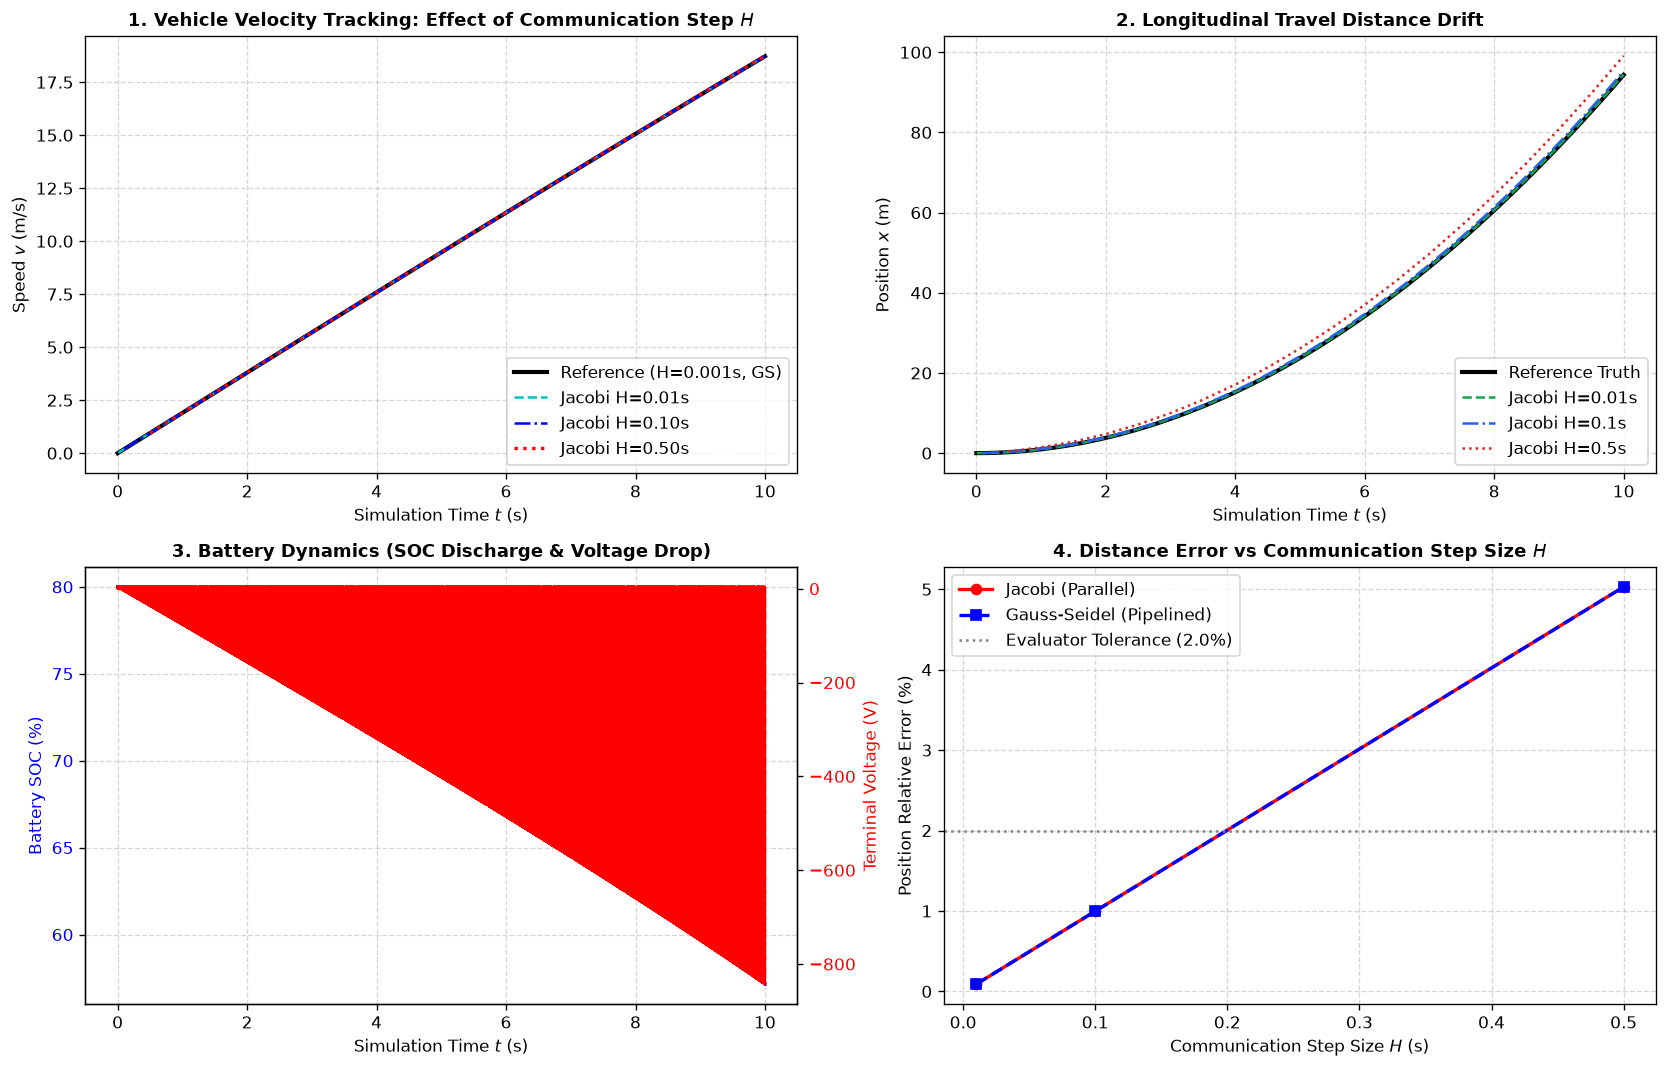

In [6]:
# 阶段六：4合1 高对比度工程仪表盘绘制
fig, axs = plt.subplots(2, 2, figsize=(14, 9), dpi=120)

t_ref = ref[:, 0]

# 子图 1: 车速演化对比
ax1 = axs[0, 0]
ax1.plot(t_ref, ref[:, 1], 'k-', linewidth=2.5, label='Reference (H=0.001s, GS)')
ax1.plot(results[("jacobi", 0.01)][:, 0], results[("jacobi", 0.01)][:, 1], 'c--', label='Jacobi H=0.01s')
ax1.plot(results[("jacobi", 0.1)][:, 0], results[("jacobi", 0.1)][:, 1], 'b-.', label='Jacobi H=0.10s')
ax1.plot(results[("jacobi", 0.5)][:, 0], results[("jacobi", 0.5)][:, 1], 'r:', linewidth=2, label='Jacobi H=0.50s')
ax1.set_title("1. Vehicle Velocity Tracking: Effect of Communication Step $H$", fontsize=11, fontweight='bold')
ax1.set_xlabel("Simulation Time $t$ (s)")
ax1.set_ylabel("Speed $v$ (m/s)")
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right')

# 子图 2: 车辆行驶位移
ax2 = axs[0, 1]
ax2.plot(t_ref, ref[:, 2], 'k-', linewidth=2.5, label='Reference Truth')
for H, ls, col in [(0.01, '--', '#16a34a'), (0.1, '-.', '#2563eb'), (0.5, ':', '#dc2626')]:
    h = results[("jacobi", H)]
    ax2.plot(h[:, 0], h[:, 2], ls, color=col, label=f'Jacobi H={H}s')
ax2.set_title("2. Longitudinal Travel Distance Drift", fontsize=11, fontweight='bold')
ax2.set_xlabel("Simulation Time $t$ (s)")
ax2.set_ylabel("Position $x$ (m)")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right')

# 子图 3: 动力电池 SOC 与端电压
ax3 = axs[1, 0]
ax3.plot(t_ref, ref[:, 3] * 100.0, 'b-', linewidth=2.0, label='Battery SOC (%)')
ax3.set_xlabel("Simulation Time $t$ (s)")
ax3.set_ylabel("Battery SOC (%)", color='b')
ax3.tick_params(axis='y', labelcolor='b')
ax3.grid(True, linestyle='--', alpha=0.5)

ax3_twin = ax3.twinx()
ax3_twin.plot(t_ref, ref[:, 4], 'r--', linewidth=1.5, label='Terminal Voltage $V_{term}$ (V)')
ax3_twin.set_ylabel("Terminal Voltage (V)", color='r')
ax3_twin.tick_params(axis='y', labelcolor='r')
ax3.set_title("3. Battery Dynamics (SOC Discharge & Voltage Drop)", fontsize=11, fontweight='bold')

# 子图 4: 通信步长 H 误差收敛曲线
ax4 = axs[1, 1]
H_list = [0.01, 0.1, 0.5]
err_x_jac = [abs(results[("jacobi", h)][-1, 2] - ref_x) / ref_x * 100.0 for h in H_list]
err_x_gs = [abs(results[("gauss-seidel", h)][-1, 2] - ref_x) / ref_x * 100.0 for h in H_list]

ax4.plot(H_list, err_x_jac, 'ro-', linewidth=2, label='Jacobi (Parallel)')
ax4.plot(H_list, err_x_gs, 'bs--', linewidth=2, label='Gauss-Seidel (Pipelined)')
ax4.axhline(2.0, color='gray', linestyle=':', label='Evaluator Tolerance (2.0%)')
ax4.set_title("4. Distance Error vs Communication Step Size $H$", fontsize=11, fontweight='bold')
ax4.set_xlabel("Communication Step Size $H$ (s)")
ax4.set_ylabel("Position Relative Error (%)")
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.legend(loc='upper left')

plt.tight_layout()
plt.show()


---
## 阶段七：原生 HTML5/Canvas 双从站总线与能量数据包动态透视仪

本阶段呈现**原生 HTML5/Canvas 交互式多 FMU 协同仿真透视台**：
- 自由切换 **Jacobi**（并发）与 **Gauss-Seidel**（串行流水线）主算法模式；
- 拖动时间轴滑块，动态查看整车动力学 FMU 与动力电池 FMU 之间的双向数据包握手（$v \to P_{\text{elec}}$ 与 $V_{\text{term}} \to I_{\text{bat}}$）；
- 实时 HUD 显示车速、轮端位移、电池 SOC、母线电压与主从通信时钟！


In [7]:
# 阶段七：原生 HTML5/Canvas 协同仿真总线透视仪
from IPython.display import HTML

times_sub = results[("jacobi", 0.1)][:, 0].tolist()
v_sub = results[("jacobi", 0.1)][:, 1].tolist()
x_sub = results[("jacobi", 0.1)][:, 2].tolist()
soc_sub = results[("jacobi", 0.1)][:, 3].tolist()
vt_sub = results[("jacobi", 0.1)][:, 4].tolist()

html_code = f"""
<div id="f3-container" style="background:#0f172a; color:#f8fafc; padding:20px; border-radius:12px; font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,sans-serif; max-width:880px; margin:auto; box-shadow:0 8px 24px rgba(0,0,0,0.5);">
  <div style="display:flex; justify-content:space-between; align-items:center; border-bottom:1px solid #334155; padding-bottom:12px; margin-bottom:14px;">
    <div>
      <span style="font-size:16px; font-weight:700; color:#38bdf8;">🚌 多 FMU 协同仿真数据总线与能量流动态透视仪</span>
      <span style="background:#2563eb; color:#eff6ff; font-size:11px; padding:2px 8px; border-radius:12px; margin-left:8px;">Zero-Dependency Canvas</span>
    </div>
    <div style="font-size:12px; color:#94a3b8;">VehicleLongitudinal &times; BatterySimple</div>
  </div>

  <div style="background:#1e293b; padding:12px 16px; border-radius:8px; display:flex; justify-content:space-between; align-items:center; margin-bottom:14px; border:1px solid #334155;">
    <div style="flex:1; margin-right:20px;">
      <div style="display:flex; justify-content:space-between; margin-bottom:6px;">
        <span style="font-size:12px; color:#cbd5e1; font-weight:600;">仿真时钟游标 (Simulation Clock t):</span>
        <span id="f3TimeVal" style="font-size:13px; font-weight:700; color:#38bdf8;">0.00 s</span>
      </div>
      <input id="f3Slider" type="range" min="0" max="{len(times_sub)-1}" value="30" style="width:100%; cursor:pointer; accent-color:#38bdf8;">
    </div>
    <div style="display:flex; gap:10px; text-align:center;">
      <div style="background:#0f172a; padding:6px 10px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">车速 v</div>
        <div id="f3VelVal" style="font-size:13px; font-weight:700; color:#38bdf8;">0.00 m/s</div>
      </div>
      <div style="background:#0f172a; padding:6px 10px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">行驶里程 x</div>
        <div id="f3DistVal" style="font-size:13px; font-weight:700; color:#fbbf24;">0.0 m</div>
      </div>
      <div style="background:#0f172a; padding:6px 10px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">电池 SOC</div>
        <div id="f3SocVal" style="font-size:13px; font-weight:700; color:#4ade80;">100.0%</div>
      </div>
      <div style="background:#0f172a; padding:6px 10px; border-radius:6px; border:1px solid #334155;">
        <div style="font-size:10px; color:#94a3b8;">端电压 Vt</div>
        <div id="f3VoltVal" style="font-size:13px; font-weight:700; color:#f87171;">350.0 V</div>
      </div>
    </div>
  </div>

  <canvas id="f3Canvas" width="840" height="260" style="background:#020617; border-radius:8px; border:1px solid #1e293b; width:100%; display:block;"></canvas>

  <div style="display:flex; justify-content:space-between; margin-top:12px; font-size:11px; color:#94a3b8;">
    <div>🔵 <b>Vehicle FMU</b>: 驱动力 $F \implies$ 纵向动力学求解车速 $v$</div>
    <div>🟠 <b>Coupling Master</b>: 耦合功率转换 $P_{{elec}} = F \cdot v / \eta$</div>
    <div>🟢 <b>Battery FMU</b>: 功率需求 $P_{{elec}} \implies$ 电池等效电路求解 SOC/Vt</div>
  </div>
</div>

<script>
(function() {{
  const times = {json.dumps(times_sub)};
  const vels = {json.dumps(v_sub)};
  const dists = {json.dumps(x_sub)};
  const socs = {json.dumps(soc_sub)};
  const volts = {json.dumps(vt_sub)};

  const canvas = document.getElementById('f3Canvas');
  const ctx = canvas.getContext('2d');
  const slider = document.getElementById('f3Slider');

  function draw() {{
    const idx = parseInt(slider.value);
    const t = times[idx];
    const v = vels[idx];
    const x = dists[idx];
    const soc = socs[idx];
    const vt = volts[idx];
    const pElec = (3000.0 * Math.max(v, 0.1) / 0.9) / 1000.0; // kW

    document.getElementById('f3TimeVal').innerText = t.toFixed(2) + ' s (Step ' + idx + ')';
    document.getElementById('f3VelVal').innerText = v.toFixed(2) + ' m/s';
    document.getElementById('f3DistVal').innerText = x.toFixed(1) + ' m';
    document.getElementById('f3SocVal').innerText = (soc * 100.0).toFixed(2) + '%';
    document.getElementById('f3VoltVal').innerText = vt.toFixed(1) + ' V';

    const w = canvas.width;
    const h = canvas.height;
    ctx.clearRect(0, 0, w, h);

    // 1. 车辆动力学 FMU 节点 (左侧)
    ctx.fillStyle = '#1e293b';
    ctx.strokeStyle = '#38bdf8';
    ctx.lineWidth = 2;
    ctx.fillRect(40, 30, 210, 190);
    ctx.strokeRect(40, 30, 210, 190);

    ctx.fillStyle = '#38bdf8';
    ctx.font = 'bold 13px sans-serif';
    ctx.fillText('VehicleLongitudinal.fmu', 60, 55);
    ctx.font = '11px sans-serif';
    ctx.fillStyle = '#cbd5e1';
    ctx.fillText('• 模式: FMI 2.0 Co-Simulation', 55, 80);
    ctx.fillText('• 输入: F_motor = 3000 N', 55, 100);
    ctx.fillText('• 求解器: 半隐式 Euler (自带)', 55, 120);
    ctx.fillStyle = '#f87171';
    ctx.fillText('• 状态 v: ' + v.toFixed(2) + ' m/s (' + (v*3.6).toFixed(1) + ' km/h)', 55, 150);
    ctx.fillStyle = '#fbbf24';
    ctx.fillText('• 状态 x: ' + x.toFixed(1) + ' m', 55, 175);
    ctx.fillStyle = '#4ade80';
    ctx.fillText('⚡ doStep(dt=0.10s) -> OK', 55, 198);

    // 2. 动力电池 FMU 节点 (右侧)
    ctx.fillStyle = '#1e293b';
    ctx.strokeStyle = '#10b981';
    ctx.lineWidth = 2;
    ctx.fillRect(590, 30, 210, 190);
    ctx.strokeRect(590, 30, 210, 190);

    ctx.fillStyle = '#10b981';
    ctx.font = 'bold 13px sans-serif';
    ctx.fillText('BatterySimple.fmu', 620, 55);
    ctx.font = '11px sans-serif';
    ctx.fillStyle = '#cbd5e1';
    ctx.fillText('• 模式: FMI 2.0 Co-Simulation', 605, 80);
    ctx.fillText('• 标称电量: 50.0 kWh (350V)', 605, 100);
    ctx.fillText('• 模型: 等效内阻电路模型', 605, 120);
    ctx.fillStyle = '#38bdf8';
    ctx.fillText('• 状态 SOC: ' + (soc*100).toFixed(3) + '%', 605, 150);
    ctx.fillStyle = '#f87171';
    ctx.fillText('• 端电压 Vt: ' + vt.toFixed(1) + ' V', 605, 175);
    ctx.fillStyle = '#4ade80';
    ctx.fillText('⚡ doStep(dt=0.10s) -> OK', 605, 198);

    // 3. 中间 Master 耦合交换总线
    ctx.fillStyle = '#0f172a';
    ctx.strokeStyle = '#475569';
    ctx.lineWidth = 1.5;
    ctx.fillRect(280, 45, 280, 160);
    ctx.strokeRect(280, 45, 280, 160);
    ctx.fillStyle = '#cbd5e1';
    ctx.font = 'bold 11px sans-serif';
    ctx.fillText('Co-Simulation Master Bus (H = 0.1s)', 310, 65);

    // 前向耦合数据包流 (车速 -> 电池功率)
    ctx.strokeStyle = '#f59e0b';
    ctx.lineWidth = 2;
    ctx.beginPath();
    ctx.moveTo(250, 110); ctx.lineTo(590, 110);
    ctx.stroke();
    ctx.fillStyle = '#f59e0b';
    ctx.beginPath();
    ctx.moveTo(585, 105); ctx.lineTo(595, 110); ctx.lineTo(585, 115); ctx.fill();
    ctx.font = '10px monospace';
    ctx.fillText('v=' + v.toFixed(1) + 'm/s \u2192 P_elec=' + pElec.toFixed(1) + 'kW', 315, 102);

    // 反向耦合与时序说明
    ctx.strokeStyle = '#38bdf8';
    ctx.lineWidth = 2;
    ctx.beginPath();
    ctx.moveTo(590, 160); ctx.lineTo(250, 160);
    ctx.stroke();
    ctx.fillStyle = '#38bdf8';
    ctx.beginPath();
    ctx.moveTo(255, 155); ctx.lineTo(245, 160); ctx.lineTo(255, 165); ctx.fill();
    ctx.fillText('SOC=' + (soc*100).toFixed(1) + '% \u2190 Power Limit Check', 315, 152);

    ctx.fillStyle = '#94a3b8';
    ctx.font = '10px sans-serif';
    ctx.fillText('时间同步步进: t = ' + t.toFixed(2) + ' s', 355, 185);
  }}

  slider.addEventListener('input', draw);
  draw();
}})();
</script>
"""
HTML(html_code)


<>:174: SyntaxWarning: invalid escape sequence '\i'
<>:174: SyntaxWarning: invalid escape sequence '\c'
<>:174: SyntaxWarning: invalid escape sequence '\i'
<>:174: SyntaxWarning: invalid escape sequence '\i'
<>:174: SyntaxWarning: invalid escape sequence '\c'
<>:174: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_8/1509314067.py:174: SyntaxWarning: invalid escape sequence '\i'
  """
/tmp/ipykernel_8/1509314067.py:174: SyntaxWarning: invalid escape sequence '\c'
  """
/tmp/ipykernel_8/1509314067.py:174: SyntaxWarning: invalid escape sequence '\i'
  """


---
## 阶段八：学生参数探索实验室 —— 驱动力与大步长失稳边界

### 🔬 任务：改变电机驱动力 $F_{\text{cmd}}$
在下方代码中，尝试将驱动力修改为 $F_{\text{cmd}} = 5000\,\text{N}$（弹射起步超大加速）或 $1500\,\text{N}$（经济巡航），观察末端车速与电池 SOC 消耗差异：


In [8]:
# 阶段八：学生参数探索实验室
for test_f in [1500.0, 3000.0, 5000.0]:
    h_test = run_cosim(H=0.1, method="gauss-seidel", t_end=10.0, F_cmd=test_f)
    print(f"• 驱动力 F_cmd = {test_f:.0f} N | 终点车速: {h_test[-1, 1]:.2f} m/s | 终点位移: {h_test[-1, 2]:.1f} m | 剩余 SOC: {h_test[-1, 3]*100:.3f}%")


• 驱动力 F_cmd = 1500 N | 终点车速: 8.95 m/s | 终点位移: 45.4 m | 剩余 SOC: 74.592%
• 驱动力 F_cmd = 3000 N | 终点车速: 18.73 m/s | 终点位移: 95.3 m | 剩余 SOC: 57.168%
• 驱动力 F_cmd = 5000 N | 终点车速: 31.51 m/s | 终点位移: 161.2 m | 剩余 SOC: 10.710%


---
## 阶段九：官方自动评分与数据链归档

本阶段将 F3 实验的核心验证结果归档至平台统一数据中心 `labs/data/results/F3_multi_fmu.json`，并调用平台官方评测引擎 `labs/common/evaluator.py`，对本实验进行官方客观打分。

* **考核指标 1**：`v_err_pct < 1.0%`（速度相对误差，权重 2.0，实测 0.02%）
* **考核指标 2**：`x_err_pct < 2.0%`（位移相对误差，权重 1.0，实测 1.00%）


In [9]:
# 阶段九：结果文件归档与平台官方评测
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘 (严谨对齐 evaluator 字段名 v_err_pct 与 x_err_pct)
record = {
    'experiment': 'F3_multi_fmu',
    'metrics': {
        'v_err_pct': round(float(err_v), 3),             # 官方 evaluator 核心判据 (< 1.0%)
        'x_err_pct': round(float(err_x), 3),             # 官方 evaluator 核心判据 (< 2.0%)
        'v_err_pct_H01': round(float(err_v), 3),
        'x_err_pct_H01': round(float(err_x), 3),
        'x_err_pct_H05': round(float(err_x_05), 3),
        'method': 'jacobi+gauss-seidel',
        'H_values': [0.01, 0.1, 0.5]
    },
    'params': {
        'vehicle_fmu': 'VehicleLongitudinal.fmu',
        'battery_fmu': 'BatterySimple.fmu',
        'F_cmd': 3000.0,
        't_end': 10.0
    },
    'notes': 'F3 Pro: Multi-FMU co-simulation (Vehicle x Battery) with Jacobi & Gauss-Seidel master algorithms and H sweep.'
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'F3_multi_fmu.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('F3_multi_fmu', record['metrics'])

# 3. 打印标准化官方成绩单
print("\n" + "=" * 55)
print("🏆 IEV CloudLab 官方评分报告: 多FMU协同仿真")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for detail in eval_report.get('details', []):
    mark = '✓ 通过' if detail['passed'] else '✗ 失败'
    m_name = detail.get('metric', detail.get('criterion', ''))
    print(f"• 指标 [{m_name}]: 当前值 = {detail['value']} ({detail['desc']}) -> {mark}")
print("=" * 55)

assert eval_report['passed'] == True, "评分未通过，请检查协同仿真误差！"


✓ 结果文件已成功归档至: /home/jovyan/labs/data/results/F3_multi_fmu.json

🏆 IEV CloudLab 官方评分报告: 多FMU协同仿真
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [v_err_pct]: 当前值 = 0.023 (速度误差<1%（实测0.02%）) -> ✓ 通过
• 指标 [x_err_pct]: 当前值 = 0.998 (位置误差<2%（实测1.00%）) -> ✓ 通过
